In [4]:
# -*- coding: utf-8 -*-
# full_pipeline_select_n_by_n_and_load_waves.py

from typing import Optional, Tuple, List, Dict
import os, re, random, h5py, hashlib
import numpy as np
import torch

# =========================
# User-configurable settings
# =========================
h5_path      = "../data/Instance_events_maggt3.hdf5"
N            = 30                 # target N x N
use_split    = False              # whether to split 80/10/10 first and search within a subset
split_name   = "train"            # "train" | "val" | "test"
segment_len  = 8192               # None means no cropping or zero-padding
normalize    = True               # whether to normalize each trace per channel
max_trials   = 300                # number of search-start attempts
seed         = 42

GLOBAL_SEED = seed
TSNE_SEED = seed

# =========================
# Reproducibility setup
# =========================
# PYTHONHASHSEED must normally be set before Python starts. We still set it here
# for subprocesses and avoid Python's salted hash() below.
os.environ["PYTHONHASHSEED"] = str(GLOBAL_SEED)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

def seed_everything(seed: int = GLOBAL_SEED, deterministic: bool = True) -> None:
    """Seed Python, NumPy, and PyTorch RNGs as far as the runtime allows."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = deterministic
    try:
        torch.use_deterministic_algorithms(deterministic, warn_only=True)
    except TypeError:
        torch.use_deterministic_algorithms(deterministic)
    except Exception:
        pass

def seed_worker(worker_id: int) -> None:
    """Seed DataLoader workers deterministically."""
    worker_seed = (GLOBAL_SEED + worker_id) % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

def stable_fraction_from_string(value: str, salt: int = 12345) -> float:
    """Stable replacement for Python's process-randomized hash()."""
    digest = hashlib.sha256(f"{salt}:{value}".encode("utf-8")).hexdigest()
    return (int(digest[:16], 16) % 1_000_000) / 1_000_000.0

seed_everything(GLOBAL_SEED)


# =========================
# Utility functions
# =========================
def _parse_trace_name(name: str) -> Tuple[str,str]:
    toks = name.split(".")
    if len(toks) >= 3 and toks[0].isdigit():
        # "10027911.IV.ARRO..EH" -> (sid='ARRO', eid='10027911')
        return toks[2], toks[0]
    tokens = re.split(r"[.\-_]+", name)
    station = tokens[2] if len(tokens) >= 3 else tokens[0]
    event = tokens[0]
    return station, event

def _fix_nan(x: np.ndarray) -> np.ndarray:
    x = x.astype(np.float32, copy=False)
    x[~np.isfinite(x)] = 0.0
    return x

def _center_crop_or_pad(x: np.ndarray, length: Optional[int]) -> np.ndarray:
    if length is None:
        return x
    C, L = x.shape
    if L == length:
        return x
    if L > length:
        start = (L - length) // 2
        return x[:, start:start+length]
    # pad
    pad = length - L
    left = pad // 2
    right = pad - left
    return np.pad(x, ((0,0), (left, right)), mode="constant")

def load_waves_for(traces_list, h5file, segment_len: Optional[int] = None, normalize: bool = False):
    """
    Returns:
      - xs: if lengths match -> torch.Tensor [N, C, L]; otherwise -> List[Tensor[C, Li]]
    """
    xs = []
    same_len = True
    L0 = None
    for t in traces_list:
        w = h5file["data"][t][()]        # [L] or [C,L]
        if w.ndim == 1:
            w = w[None, :]
        w = _fix_nan(w.astype(np.float32))
        w = _center_crop_or_pad(w, segment_len)
        x = torch.tensor(w, dtype=torch.float32)  # [C, L]
        if normalize:
            mean = x.mean(dim=-1, keepdim=True)
            std  = x.std(dim=-1, keepdim=True).clamp_min(1e-6)
            x = (x - mean) / std
        xs.append(x)
        L = x.shape[-1]
        if L0 is None: L0 = L
        elif L != L0: same_len = False

    if same_len:
        try:
            xs = torch.stack(xs, dim=0)  # [N, C, L]
        except Exception:
            pass
    return xs

def split_masks_by_hash(names: np.ndarray, train_portion=0.8, val_portion=0.1):
    # Use a stable cryptographic hash instead of Python's salted hash(),
    # so the split is identical across interpreter restarts.
    vals = np.array([stable_fraction_from_string(str(n)) for n in names], dtype=float)
    tr_m = vals < train_portion
    va_m = (~tr_m) & (vals < train_portion + val_portion)
    te_m = ~(tr_m | va_m)
    return tr_m, va_m, te_m

from collections import defaultdict

def find_n_by_n_block(eids, sids, N, max_trials=200, seed=0):
    """
    Find N eids and N sids in the (eids, sids) samples,
    such that every (sid, eid) pair has at least one sample.
    Return the selected N^2 local indices (one per pair), or None if not found.
    """
    rng = random.Random(seed)
    eids = np.asarray(eids).astype(str)
    sids = np.asarray(sids).astype(str)
    n = len(eids)
    assert len(sids) == n

    # 1) pair -> indices
    pair_to_idx = defaultdict(list)
    for i, (e, s) in enumerate(zip(eids, sids)):
        pair_to_idx[(s, e)].append(i)

    # 2) Adjacency
    sid_to_eids = defaultdict(set)
    eid_to_sids = defaultdict(set)
    for (s, e), idxs in pair_to_idx.items():
        sid_to_eids[s].add(e)
        eid_to_sids[e].add(s)

    sids_sorted = sorted(sid_to_eids.keys(), key=lambda s: -len(sid_to_eids[s]))
    eids_sorted = sorted(eid_to_sids.keys(), key=lambda e: -len(eid_to_sids[e]))

    cand_sids_all = list(sids_sorted)

    for _ in range(max_trials):
        rng.shuffle(cand_sids_all)
        for start_sid in cand_sids_all:
            chosen_sids = [start_sid]
            common_eids = set(sid_to_eids[start_sid])

            for sid in sids_sorted:
                if sid in chosen_sids:
                    continue
                inter = common_eids & sid_to_eids[sid]
                if len(inter) >= N:
                    chosen_sids.append(sid)
                    common_eids = inter
                    if len(chosen_sids) == N:
                        break

            if len(chosen_sids) < N or len(common_eids) < N:
                continue

            chosen_eids = sorted(list(common_eids), key=lambda e: -len(eid_to_sids[e]))[:N]

            chosen_indices = []
            for sid in chosen_sids:
                for eid in chosen_eids:
                    idxs = pair_to_idx.get((sid, eid), [])
                    if not idxs:
                        chosen_indices = None
                        break
                    chosen_indices.append(idxs[0])
                if chosen_indices is None:
                    break

            if chosen_indices is not None and len(chosen_indices) == N*N:
                return sorted(set(chosen_indices))

    return None

# =========================
# Read H5 data and metadata
# =========================
h5 = h5py.File(h5_path, "r")

if "meta" in h5 and "events" in h5["meta"] and "columns" in h5["meta"]:
    meta = h5["meta"]["events"][()]
    cols = [c.decode() if isinstance(c, (bytes, np.bytes_)) else str(c) for c in h5["meta"]["columns"][()]]
    def idx_of(cands):
        for c in cands:
            if c in cols: return cols.index(c)
        return None
    i_tr = idx_of(("trace_name","trace"))
    i_sid= idx_of(("station_id","sid","station"))
    i_eid= idx_of(("event_id","eid","event"))
    i_fs = idx_of(("sampling_rate","fs"))

    if i_tr is None or i_sid is None or i_eid is None:
        raise KeyError("meta/columns is missing trace_name/sid/eid")

    traces = np.asarray(meta[:, i_tr]).astype(str)
    sids   = np.asarray(meta[:, i_sid]).astype(str)
    eids   = np.asarray(meta[:, i_eid]).astype(str)
    if i_fs is not None:
        fses = np.asarray(meta[:, i_fs], dtype=float)
    else:
        fses = np.array([h5["data"][t].attrs.get("fs", h5["data"][t].attrs.get("sampling_rate", 100.0)) for t in traces], dtype=float)
else:
    # derive from /data
    keys = list(h5["data"].keys())
    traces = np.array(keys).astype(str)
    sids = []; eids = []; fses = []
    for k in keys:
        ds = h5["data"][k]
        attrs = {str(a).lower(): ds.attrs[a] for a in ds.attrs.keys()}
        sid = attrs.get("station_id", attrs.get("sid", attrs.get("station", None)))
        eid = attrs.get("event_id",   attrs.get("eid", attrs.get("event", None)))
        fs  = attrs.get("sampling_rate", attrs.get("fs", 100.0))
        if sid is None or eid is None:
            sid2, eid2 = _parse_trace_name(k)
            sid = sid if sid is not None else sid2
            eid = eid if eid is not None else eid2
        sids.append(str(sid)); eids.append(str(eid)); fses.append(float(fs))
    sids = np.array(sids); eids = np.array(eids); fses = np.array(fses, dtype=float)
    meta = None

print(f"Full dataset: rows={len(traces)}, unique_eids={len(np.unique(eids))}, unique_sids={len(np.unique(sids))}")

# =========================
# Find/cache largest complete station x event block
# =========================

from pathlib import Path
from collections import defaultdict
import hashlib
import json
import numpy as np
import random

# -------------------------
# Block-selection settings
# -------------------------
# This replaces the old fixed N x N search.
# It searches for a complete station x event rectangle:
# every selected station has every selected event.

block_cache_dir = Path("outputs_1d/block_cache")
block_cache_dir.mkdir(parents=True, exist_ok=True)

force_recompute_block = False

# Optional constraints to avoid degenerate rectangles like 2 stations x 5000 events.
min_n_stations = 5
min_n_events = 5
max_aspect_ratio = 1.0

# Search controls.
# This is a deterministic greedy search, not a mathematical proof of optimality.
search_seed_limit = 500
search_random_restarts = 50

# Reuse existing config values if they exist.
seed = globals().get("seed", 42)
use_split = globals().get("use_split", False)
split_name = globals().get("split_name", "train")

rng = random.Random(seed)


def _stable_fraction_from_string(value: str, salt: int = 12345) -> float:
    """Stable replacement for Python's process-randomized hash()."""
    digest = hashlib.sha256(f"{salt}:{value}".encode("utf-8")).hexdigest()
    return (int(digest[:16], 16) % 1_000_000) / 1_000_000.0


def _split_masks_by_hash_if_needed(names: np.ndarray, train_portion=0.8, val_portion=0.1):
    """
    Stable train/val/test split based on trace names.
    Used only if split_masks_by_hash is not already defined.
    """
    vals = np.array([_stable_fraction_from_string(str(n)) for n in names], dtype=float)
    tr_m = vals < train_portion
    va_m = (~tr_m) & (vals < train_portion + val_portion)
    te_m = ~(tr_m | va_m)
    return tr_m, va_m, te_m


def _make_search_mask(traces, use_split: bool, split_name: str):
    """Return the rows on which the block search should run."""
    if not use_split:
        return np.ones(len(traces), dtype=bool)

    if "split_masks_by_hash" in globals():
        tr_m, va_m, te_m = split_masks_by_hash(traces, 0.8, 0.1)
    else:
        tr_m, va_m, te_m = _split_masks_by_hash_if_needed(traces, 0.8, 0.1)

    if split_name == "train":
        return tr_m
    if split_name == "val":
        return va_m
    if split_name == "test":
        return te_m

    raise ValueError(f"Unknown split_name={split_name!r}; expected 'train', 'val', or 'test'.")


def _dataset_signature(traces, eids, sids, search_mask):
    """
    Create a compact signature so cached blocks are reused only for the same
    dataset/split content.
    """
    h = hashlib.sha256()

    h.update(str(len(traces)).encode("utf-8"))
    h.update(b"\n")

    idx = np.nonzero(search_mask)[0]
    for i in idx:
        h.update(str(traces[i]).encode("utf-8"))
        h.update(b"\t")
        h.update(str(eids[i]).encode("utf-8"))
        h.update(b"\t")
        h.update(str(sids[i]).encode("utf-8"))
        h.update(b"\n")

    return h.hexdigest()[:16]


def _build_pair_graph(eids_local, sids_local):
    """
    Build bipartite graph:
        station -> events
        event   -> stations
        pair    -> row indices
    """
    eids_local = np.asarray(eids_local).astype(str)
    sids_local = np.asarray(sids_local).astype(str)

    pair_to_idx = defaultdict(list)
    sid_to_eids = defaultdict(set)
    eid_to_sids = defaultdict(set)

    for i, (eid, sid) in enumerate(zip(eids_local, sids_local)):
        pair_to_idx[(sid, eid)].append(i)
        sid_to_eids[sid].add(eid)
        eid_to_sids[eid].add(sid)

    return pair_to_idx, sid_to_eids, eid_to_sids


def _aspect_ok(n_left, n_right, max_aspect_ratio):
    if n_left <= 0 or n_right <= 0:
        return False
    ratio = max(n_left / n_right, n_right / n_left)
    return ratio <= max_aspect_ratio


def _block_score(n_stations, n_events):
    # Primary objective: maximize selected trace count.
    # Secondary objective: prefer less degenerate blocks.
    area = n_stations * n_events
    balance = min(n_stations, n_events)
    aspect = max(n_stations / n_events, n_events / n_stations)
    return (area, balance, -aspect)


def _update_best(best, stations, events, min_n_stations, min_n_events, max_aspect_ratio):
    n_stations = len(stations)
    n_events = len(events)

    if n_stations < min_n_stations:
        return best
    if n_events < min_n_events:
        return best
    if not _aspect_ok(n_stations, n_events, max_aspect_ratio):
        return best

    candidate = {
        "stations": tuple(sorted(stations)),
        "events": tuple(sorted(events)),
        "n_stations": n_stations,
        "n_events": n_events,
        "area": n_stations * n_events,
        "score": _block_score(n_stations, n_events),
    }

    if best is None or candidate["score"] > best["score"]:
        return candidate

    return best


def _greedy_search_left_to_right(
    left_to_right,
    left_kind: str,
    min_left: int,
    min_right: int,
    max_aspect_ratio: float,
    seed: int,
    search_seed_limit: int = 500,
    search_random_restarts: int = 50,
):
    """
    Greedy complete-biclique search.

    If left_kind == "station":
        left nodes are stations and right nodes are events.

    If left_kind == "event":
        left nodes are events and right nodes are stations.

    The returned object is still normalized to:
        stations, events
    """
    rng = random.Random(seed)

    all_left = sorted(
        left_to_right.keys(),
        key=lambda x: (-len(left_to_right[x]), str(x))
    )

    if len(all_left) == 0:
        return None

    ranked_seeds = all_left[:search_seed_limit]

    extra_seeds = []
    remaining = all_left[search_seed_limit:]
    for _ in range(search_random_restarts):
        if not remaining:
            break
        extra_seeds.append(rng.choice(remaining))

    seed_nodes = list(dict.fromkeys(ranked_seeds + extra_seeds))

    best = None

    for start in seed_nodes:
        chosen_left = [start]
        common_right = set(left_to_right[start])
        unused_left = [x for x in all_left if x != start]

        if left_kind == "station":
            best = _update_best(
                best,
                stations=chosen_left,
                events=common_right,
                min_n_stations=min_left,
                min_n_events=min_right,
                max_aspect_ratio=max_aspect_ratio,
            )
        else:
            best = _update_best(
                best,
                stations=common_right,
                events=chosen_left,
                min_n_stations=min_right,
                min_n_events=min_left,
                max_aspect_ratio=max_aspect_ratio,
            )

        while True:
            best_next = None

            for cand in unused_left:
                inter = common_right & left_to_right[cand]
                if len(inter) == 0:
                    continue

                n_left = len(chosen_left) + 1
                n_right = len(inter)

                # We allow intermediate imbalanced states because later additions
                # may improve the rectangle. The priority still favors large area.
                priority = (
                    n_left * n_right,
                    min(n_left, n_right),
                    -max(n_left / max(1, n_right), n_right / max(1, n_left)),
                    len(left_to_right[cand]),
                    str(cand),
                )

                if best_next is None or priority > best_next["priority"]:
                    best_next = {
                        "node": cand,
                        "inter": inter,
                        "priority": priority,
                    }

            if best_next is None:
                break

            chosen_left.append(best_next["node"])
            common_right = best_next["inter"]
            unused_left.remove(best_next["node"])

            if left_kind == "station":
                best = _update_best(
                    best,
                    stations=chosen_left,
                    events=common_right,
                    min_n_stations=min_left,
                    min_n_events=min_right,
                    max_aspect_ratio=max_aspect_ratio,
                )
            else:
                best = _update_best(
                    best,
                    stations=common_right,
                    events=chosen_left,
                    min_n_stations=min_right,
                    min_n_events=min_left,
                    max_aspect_ratio=max_aspect_ratio,
                )

    return best


def find_largest_complete_station_event_block(
    eids_local,
    sids_local,
    min_n_stations=5,
    min_n_events=5,
    max_aspect_ratio=10.0,
    seed=42,
    search_seed_limit=500,
    search_random_restarts=50,
):
    """
    Find a large complete station x event rectangle.

    Returns:
        block dict with:
            stations
            events
            local_indices
            n_stations
            n_events
            area

    Note:
        Finding the true maximum complete bipartite subgraph is hard.
        This function uses a deterministic greedy/restart heuristic.
    """
    pair_to_idx, sid_to_eids, eid_to_sids = _build_pair_graph(eids_local, sids_local)

    # Search from station side.
    best_station_first = _greedy_search_left_to_right(
        left_to_right=sid_to_eids,
        left_kind="station",
        min_left=min_n_stations,
        min_right=min_n_events,
        max_aspect_ratio=max_aspect_ratio,
        seed=seed,
        search_seed_limit=search_seed_limit,
        search_random_restarts=search_random_restarts,
    )

    # Search from event side too; this can find different rectangles.
    best_event_first = _greedy_search_left_to_right(
        left_to_right=eid_to_sids,
        left_kind="event",
        min_left=min_n_events,
        min_right=min_n_stations,
        max_aspect_ratio=max_aspect_ratio,
        seed=seed + 1,
        search_seed_limit=search_seed_limit,
        search_random_restarts=search_random_restarts,
    )

    candidates = [b for b in [best_station_first, best_event_first] if b is not None]
    if not candidates:
        return None

    best = max(candidates, key=lambda b: b["score"])

    stations = list(best["stations"])
    events = list(best["events"])

    local_indices = []
    for sid in stations:
        for eid in events:
            idxs = pair_to_idx.get((sid, eid), [])
            if len(idxs) == 0:
                raise RuntimeError("Internal error: selected block is not complete.")
            local_indices.append(idxs[0])  # one trace per station-event pair

    best["local_indices"] = np.asarray(local_indices, dtype=int)
    best["stations"] = np.asarray(stations, dtype=object)
    best["events"] = np.asarray(events, dtype=object)
    best["n_stations"] = len(stations)
    best["n_events"] = len(events)
    best["area"] = len(stations) * len(events)

    return best


# -------------------------
# Choose search subset
# -------------------------
search_mask = _make_search_mask(traces, use_split=use_split, split_name=split_name)
base_positions = np.nonzero(search_mask)[0]

if len(base_positions) == 0:
    raise RuntimeError("Search mask is empty; cannot find a station-event block.")

traces_search = traces[search_mask]
eids_search = np.asarray(eids[search_mask]).astype(str)
sids_search = np.asarray(sids[search_mask]).astype(str)

print(
    f"Block search subset: rows={len(traces_search)}, "
    f"unique_events={len(np.unique(eids_search))}, "
    f"unique_stations={len(np.unique(sids_search))}, "
    f"use_split={use_split}, split_name={split_name}"
)

# -------------------------
# Cache path
# -------------------------
sig = _dataset_signature(traces, eids, sids, search_mask)
cache_file = block_cache_dir / (
    f"largest_complete_station_event_block_"
    f"sig-{sig}_"
    f"split-{split_name if use_split else 'full'}_"
    f"mins-{min_n_stations}x{min_n_events}_"
    f"aspect-{max_aspect_ratio}_"
    f"seed-{seed}.npz"
)

summary_file = cache_file.with_suffix(".json")

# -------------------------
# Load from cache or compute
# -------------------------
if cache_file.exists() and not force_recompute_block:
    cached = np.load(cache_file, allow_pickle=True)

    idx_global = cached["idx_global"].astype(int)
    block_stations = cached["stations"].astype(str)
    block_events = cached["events"].astype(str)

    block = {
        "stations": block_stations,
        "events": block_events,
        "n_stations": int(cached["n_stations"]),
        "n_events": int(cached["n_events"]),
        "area": int(cached["area"]),
        "idx_global": idx_global,
    }

    print(f"Loaded cached block from: {cache_file}")

else:
    print("Computing largest complete station x event block...")

    block = find_largest_complete_station_event_block(
        eids_local=eids_search,
        sids_local=sids_search,
        min_n_stations=min_n_stations,
        min_n_events=min_n_events,
        max_aspect_ratio=max_aspect_ratio,
        seed=seed,
        search_seed_limit=search_seed_limit,
        search_random_restarts=search_random_restarts,
    )

    if block is None:
        raise RuntimeError(
            "Could not find a complete station x event block with the requested "
            f"constraints: min_n_stations={min_n_stations}, "
            f"min_n_events={min_n_events}, max_aspect_ratio={max_aspect_ratio}. "
            "Try lowering the minimums or increasing max_aspect_ratio."
        )

    idx_local = block["local_indices"].astype(int)
    idx_global = base_positions[idx_local]

    block["idx_global"] = idx_global

    np.savez_compressed(
        cache_file,
        idx_global=idx_global,
        stations=np.asarray(block["stations"], dtype=object),
        events=np.asarray(block["events"], dtype=object),
        n_stations=np.asarray(block["n_stations"]),
        n_events=np.asarray(block["n_events"]),
        area=np.asarray(block["area"]),
    )

    summary = {
        "cache_file": str(cache_file),
        "dataset_signature": sig,
        "use_split": bool(use_split),
        "split_name": str(split_name),
        "min_n_stations": int(min_n_stations),
        "min_n_events": int(min_n_events),
        "max_aspect_ratio": float(max_aspect_ratio),
        "n_stations": int(block["n_stations"]),
        "n_events": int(block["n_events"]),
        "area": int(block["area"]),
        "seed": int(seed),
    }

    with open(summary_file, "w") as f:
        json.dump(summary, f, indent=2)

    print(f"Saved block cache to: {cache_file}")
    print(f"Saved block summary to: {summary_file}")

# -------------------------
# Build global selection mask
# -------------------------
idx_global = np.asarray(block["idx_global"], dtype=int)

if idx_global.min() < 0 or idx_global.max() >= len(traces):
    raise RuntimeError("Cached block indices are out of bounds for the current dataset.")

mask = np.zeros(len(traces), dtype=bool)
mask[idx_global] = True

# =========================
# Apply one consistent filter and read waveforms
# =========================

traces_sel = traces[mask]
eids_sel   = np.asarray(eids[mask]).astype(str)
sids_sel   = np.asarray(sids[mask]).astype(str)
fses_sel   = fses[mask]
meta_sel   = (meta[mask, :] if meta is not None else None)

expected = int(block["n_stations"]) * int(block["n_events"])

print("")
print("Selected complete station x event block")
print("---------------------------------------")
print(f"Stations:      {block['n_stations']}")
print(f"Events:        {block['n_events']}")
print(f"Rows selected: {len(traces_sel)}")
print(f"Expected rows: {expected}")
print(f"Cache file:    {cache_file}")

ue, ce = np.unique(eids_sel, return_counts=True)
us, cs = np.unique(sids_sel, return_counts=True)

print("")
print("Block balance checks")
print("--------------------")
print("Unique eids:", len(ue), "event count set:", set(ce))
print("Unique sids:", len(us), "station count set:", set(cs))

assert len(traces_sel) == expected, "Selected row count does not match station x event block size."
assert len(ue) == int(block["n_events"]), "Event count mismatch."
assert len(us) == int(block["n_stations"]), "Station count mismatch."
assert set(ce) == {int(block["n_stations"])}, "Each event should appear once per selected station."
assert set(cs) == {int(block["n_events"])}, "Each station should appear once per selected event."

# Read corresponding waveforms aligned with traces_sel order.
xs = load_waves_for(
    traces_sel,
    h5,
    segment_len=segment_len,
    normalize=normalize
)

print("")
print("Waveform load")
print("-------------")
print(
    "xs type:",
    type(xs),
    " shape:",
    (xs.shape if isinstance(xs, torch.Tensor) else f"list(len={len(xs)})")
)

# ========== Ready for downstream use ==========
# traces_sel, eids_sel, sids_sel, fses_sel, meta_sel, xs


Full dataset: rows=130037, unique_eids=2718, unique_sids=603
Block search subset: rows=130037, unique_events=2718, unique_stations=603, use_split=False, split_name=train
Computing largest complete station x event block...


Saved block cache to: outputs_1d/block_cache/largest_complete_station_event_block_sig-072f1c058b679329_split-full_mins-5x5_aspect-1.0_seed-42.npz
Saved block summary to: outputs_1d/block_cache/largest_complete_station_event_block_sig-072f1c058b679329_split-full_mins-5x5_aspect-1.0_seed-42.json

Selected complete station x event block
---------------------------------------
Stations:      34
Events:        34
Rows selected: 1156
Expected rows: 1156
Cache file:    outputs_1d/block_cache/largest_complete_station_event_block_sig-072f1c058b679329_split-full_mins-5x5_aspect-1.0_seed-42.npz

Block balance checks
--------------------
Unique eids: 34 event count set: {np.int64(34)}
Unique sids: 34 station count set: {np.int64(34)}

Waveform load
-------------
xs type: <class 'torch.Tensor'>  shape: torch.Size([1156, 3, 8192])


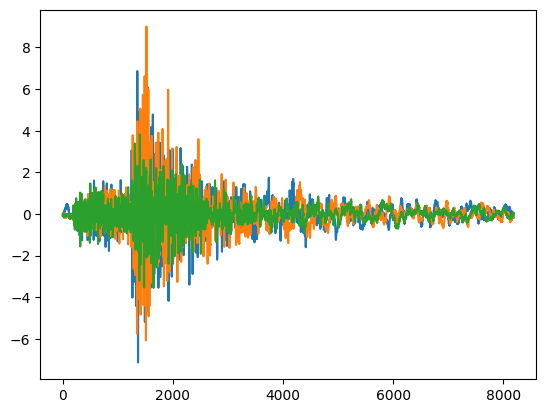

In [5]:
import matplotlib.pyplot as plt
plt.plot(xs[0,0,:])
plt.plot(xs[0,1,:])
plt.plot(xs[0,2,:])

In [6]:
from model import AE1D_Conv_MLP

In [7]:
device = "cuda:2" if torch.cuda.is_available() else "cpu"

In [8]:
# # ===== AE1D_Conv_MLP training (90/10 split + DataLoader + MSE) =====

# import torch
# from torch import nn
# from torch.utils.data import Dataset, DataLoader
# import numpy as np
# from typing import List, Tuple

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1) 90/10 split (reproducible)
# N_total = len(xs)
# rng = np.random.default_rng(1234)
# perm = rng.permutation(N_total)
# cut = int(0.9 * N_total)
# train_idx, val_idx = perm[:cut], perm[cut:]

# def _index_xs(xs, idx):
#     if isinstance(xs, torch.Tensor):
#         return xs[idx]
#     else:
#         return [xs[i] for i in idx]

# xs_train = _index_xs(xs, train_idx)
# xs_val   = _index_xs(xs, val_idx)

# # 2) Dataset + collate (zero-pad to the batch max length when xs is a list with unequal lengths)
# class XsOnlyDataset(Dataset):
#     def __init__(self, xs):
#         self.xs = xs
#     def __len__(self): return len(self.xs) if not isinstance(self.xs, torch.Tensor) else self.xs.size(0)
#     def __getitem__(self, i):
#         x = self.xs[i] if not isinstance(self.xs, torch.Tensor) else self.xs[i]
#         return x  # Tensor [C, L] or numpy -> converted to torch in collate below

# def pad_collate(batch: List[torch.Tensor]):
#     # batch: list of Tensor[C,L]
#     xs = []
#     for x in batch:
#         if isinstance(x, np.ndarray):
#             x = torch.tensor(x, dtype=torch.float32)
#         xs.append(x)
#     C = xs[0].shape[0]
#     lengths = [x.shape[-1] for x in xs]
#     Lmax = max(lengths)
#     same = all(L == Lmax for L in lengths)
#     if same:
#         x_batch = torch.stack(xs, dim=0)   # [B,C,L]
#     else:
#         B = len(xs)
#         x_batch = xs[0].new_zeros((B, C, Lmax))
#         for i, x in enumerate(xs):
#             L = x.shape[-1]
#             x_batch[i, :, :L] = x
#     return x_batch

# train_loader = DataLoader(XsOnlyDataset(xs_train), batch_size=128, shuffle=True,  num_workers=0, collate_fn=pad_collate)
# val_loader   = DataLoader(XsOnlyDataset(xs_val),   batch_size=128, shuffle=False, num_workers=0, collate_fn=pad_collate)

# # 3) Initialize the model (using your interface)
# #    Note: xs may be a list, so infer C and L from one batch first
# with torch.no_grad():
#     sample_x = next(iter(train_loader))    # [B,C,L]
# C = sample_x.shape[1]
# L = sample_x.shape[2]

# model = AE1D_Conv_MLP(C, L).to(device)    # your interface: AE1D_Conv_MLP(xs.shape[1], xs.shape[2])
# opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
# mse = nn.MSELoss()

# @torch.no_grad()
# def eval_epoch(loader):
#     model.eval()
#     total = 0
#     loss_sum = 0.0
#     for x in loader:
#         x = x.to(device, non_blocking=True)
#         out = model(x)
#         recon = out[0] if isinstance(out, (tuple, list)) else out
#         loss = mse(recon, x)
#         loss_sum += loss.item() * x.size(0)
#         total += x.size(0)
#     return loss_sum / max(1, total)

# # 4) Training
# epochs = 200
# for ep in range(1, epochs+1):
#     model.train()
#     train_loss_sum, train_total = 0.0, 0
#     for x in train_loader:
#         x = x.to(device, non_blocking=True)
#         out = model(x)
#         recon = out[0] if isinstance(out, (tuple, list)) else out
#         loss = mse(recon, x)

#         opt.zero_grad(set_to_none=True)
#         loss.backward()
#         opt.step()

#         train_loss_sum += loss.item() * x.size(0)
#         train_total += x.size(0)

#     train_loss = train_loss_sum / max(1, train_total)
#     val_loss   = eval_epoch(val_loader)
#     print(f"[Epoch {ep:02d}] train_MSE={train_loss:.6f}  val_MSE={val_loss:.6f}")


# # 5) If you still want a full-batch forward pass:
# Xs_input = xs if isinstance(xs, torch.Tensor) else pad_collate(xs)  # pad the list
# Xs_input = Xs_input.to(device)
# recon = model(Xs_input)
# recon = recon[0] if isinstance(recon, (tuple, list)) else recon
# loss = ((recon - Xs_input)**2).mean()
# print("Full-batch recon MSE:", loss.item())


In [9]:
import torch
from typing import Union, List

def pairwise_equal_matrix(id_list: Union[List[str], List[int], torch.Tensor],
                          same_val: float = 1.0,
                          diff_val: float = -1.0,
                          diag_val: float = 0.0) -> torch.Tensor:
    """
    Build an NxN matrix:
      - same id -> same_val
      - different ids -> diff_val
      - self-pairs (diagonal) -> diag_val

    Args:
        id_list: list[str] / list[int] / torch.Tensor[int]
        same_val: value for matching ids (default 1.0)
        diff_val: value for different ids (default -1.0)
        diag_val: diagonal value (default 0.0)

    Returns:
        torch.Tensor [N, N], dtype=float
    """
    # Convert to integer labels deterministically. The equality matrix is the
    # same either way, but sorted labels make debugging and reruns stable.
    if isinstance(id_list, torch.Tensor):
        ids = id_list.clone().long()
    else:
        if len(id_list) == 0:
            return torch.empty((0, 0), dtype=torch.float32)

        if isinstance(id_list[0], str) or isinstance(id_list[0], np.str_):
            labels = [str(v) for v in id_list]
            uniq = {v: i for i, v in enumerate(sorted(set(labels)))}
            ids = torch.tensor([uniq[v] for v in labels], dtype=torch.long)
        else:
            ids = torch.tensor(id_list, dtype=torch.long)

    N = len(ids)
    eq = (ids[:, None] == ids[None, :])  # bool matrix
    M = torch.full((N, N), fill_value=diff_val, dtype=torch.float32)
    M[eq] = same_val
    # Set the diagonal
    idx = torch.arange(N)
    M[idx, idx] = diag_val
    return M


In [10]:
# ====== 0) Label mapping: strings -> integer ids (useful for cross-entropy, contrastive learning, etc.) ======
from typing import List, Tuple, Dict
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

In [11]:
# ====== 90/10 split ======
seed_everything(GLOBAL_SEED)

N_total = len(xs)
rng = np.random.default_rng(GLOBAL_SEED)
perm = rng.permutation(N_total)
cut = int(0.9 * N_total)
train_idx, val_idx = perm[:cut], perm[cut:]

def _index(xs, idx):
    if isinstance(xs, torch.Tensor):
        return xs[idx]
    else:
        return [xs[i] for i in idx]

xs_train   = _index(xs, train_idx)
xs_val     = _index(xs, val_idx)
eids_train = [str(eids_sel[i]) for i in train_idx]
eids_val   = [str(eids_sel[i]) for i in val_idx]
sids_train = [str(sids_sel[i]) for i in train_idx]
sids_val   = [str(sids_sel[i]) for i in val_idx]

# ====== Dataset + collate ======
class XsWithLabels(Dataset):
    def __init__(self, xs, eids, sids):
        self.xs = xs
        self.eids = [str(v) for v in eids]
        self.sids = [str(v) for v in sids]
        assert len(xs) == len(eids) == len(sids)

    def __len__(self):
        return len(self.xs)

    def __getitem__(self, i):
        x = self.xs[i] if not isinstance(self.xs, torch.Tensor) else self.xs[i]
        if isinstance(x, np.ndarray):
            x = torch.tensor(x, dtype=torch.float32)
        return x, self.eids[i], self.sids[i]  # return Python strings

def pad_collate(batch):
    xs, eids, sids = zip(*batch)
    xs_t = []
    for x in xs:
        if isinstance(x, np.ndarray):
            x = torch.tensor(x, dtype=torch.float32)
        xs_t.append(x)
    C = xs_t[0].shape[0]
    Ls = [x.shape[-1] for x in xs_t]
    Lmax = max(Ls)
    if all(L == Lmax for L in Ls):
        x_batch = torch.stack(xs_t, dim=0)   # [B,C,L]
    else:
        B = len(xs_t)
        x_batch = xs_t[0].new_zeros((B, C, Lmax))
        for i, x in enumerate(xs_t):
            L = x.shape[-1]
            x_batch[i, :, :L] = x
    return x_batch, list(eids), list(sids)

BATCH_SIZE = 128
train_dataset = XsWithLabels(xs_train, eids_train, sids_train)
val_dataset = XsWithLabels(xs_val, eids_val, sids_val)

def make_data_loader(dataset, batch_size=BATCH_SIZE, shuffle=False, seed=GLOBAL_SEED):
    # Recreate the generator whenever you recreate the loader. This makes the
    # shuffled training order reproducible across full notebook reruns and also
    # across reruns of the training cell itself.
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        collate_fn=pad_collate,
        generator=generator,
        worker_init_fn=seed_worker,
    )

# Shuffled loader for training.
train_loader = make_data_loader(train_dataset, shuffle=True, seed=GLOBAL_SEED)

# Non-shuffled loaders for deterministic evaluation, metrics, and plotting.
train_loader_eval = make_data_loader(train_dataset, shuffle=False, seed=GLOBAL_SEED)
val_loader = make_data_loader(val_dataset, shuffle=False, seed=GLOBAL_SEED)
val_loader_eval = val_loader

# ====== Test one deterministic batch ======
xb, eids_b, sids_b = next(iter(train_loader_eval))
print("N_total:", N_total)
print("train samples:", len(train_dataset))
print("val samples:", len(val_dataset))
print("train batches:", len(train_loader))
print("val batches:", len(val_loader))
print("xb:", xb.shape)
print("eids_b[:3]:", eids_b[:3])
print("sids_b[:3]:", sids_b[:3])


N_total: 1156
train samples: 1040
val samples: 116
train batches: 9
val batches: 1
xb: torch.Size([128, 3, 8192])
eids_b[:3]: ['9980581', '10674861', '9109821']
sids_b[:3]: ['FDMO', 'GIGS', 'MURB']


In [12]:
from torch import nn

In [13]:
seed_everything(GLOBAL_SEED)
train_loader = make_data_loader(train_dataset, shuffle=True, seed=GLOBAL_SEED)
with torch.no_grad():
    sample_x = next(iter(train_loader_eval))    # [B,C,L]
C = sample_x[0].shape[1]
L = sample_x[0].shape[2]

model = AE1D_Conv_MLP(C, L).to(device)    # your interface: AE1D_Conv_MLP(xs.shape[1], xs.shape[2])
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
mse = nn.MSELoss()

@torch.no_grad()
def eval_epoch(loader):
    model.eval()
    total = 0
    loss_sum = 0.0
    for data in loader:
        x=data[0]
        x = x.to(device, non_blocking=True)
        out = model(x)
        recon = out[0] if isinstance(out, (tuple, list)) else out
        loss = mse(recon, x)
        loss_sum += loss.item() * x.size(0)
        total += x.size(0)
    return loss_sum / max(1, total)

# 4) Training
epochs = 200
same_val=100
diff_val=-1
for ep in range(1, epochs+1):
    model.train()
    train_loss_sum, train_total = 0.0, 0
    for data in train_loader:
        x=data[0]
        eids_b,sids_b=data[1],data[2]
        x = x.to(device, non_blocking=True)
        out = model(x)
        recon = out[0] if isinstance(out, (tuple, list)) else out
        z=out[1]
        B,L=z.shape
        zs=z[:,L//2:]
        ze=z[:,:L//2]
        rloss = mse(recon, x)
        s_loss=zs@zs.T
        e_loss=ze@ze.T
        matrix_e=pairwise_equal_matrix(id_list=eids_b,same_val= same_val,diff_val = diff_val).to(device)
        matrix_s=pairwise_equal_matrix(id_list=sids_b,same_val= same_val,diff_val = diff_val).to(device)
        
        closs= (s_loss*matrix_s+e_loss*matrix_e).mean()
        
        loss=rloss-closs
        
        
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        train_loss_sum += loss.item() * x.size(0)
        train_total += x.size(0)

    train_loss = train_loss_sum / max(1, train_total)
    val_loss   = eval_epoch(val_loader)
    print(f"[Epoch {ep:02d}] rloss={rloss:.6f},closs={closs:.6f},loss={loss:.6f}  val_MSE={val_loss:.6f}")

[Epoch 01] rloss=1.014075,closs=9.171871,loss=-8.157796  val_MSE=0.980885
[Epoch 02] rloss=0.984128,closs=2.859374,loss=-1.875247  val_MSE=0.978971
[Epoch 03] rloss=0.982732,closs=0.492188,loss=0.490544  val_MSE=0.977101
[Epoch 04] rloss=1.008342,closs=3.648437,loss=-2.640094  val_MSE=0.975145
[Epoch 05] rloss=0.992568,closs=2.070312,loss=-1.077744  val_MSE=0.972931
[Epoch 06] rloss=0.971932,closs=2.070312,loss=-1.098380  val_MSE=0.970297
[Epoch 07] rloss=0.995404,closs=1.281250,loss=-0.285846  val_MSE=0.967644
[Epoch 08] rloss=0.963126,closs=0.492187,loss=0.470939  val_MSE=0.967228
[Epoch 09] rloss=0.961614,closs=2.070312,loss=-1.108698  val_MSE=0.966795
[Epoch 10] rloss=0.999712,closs=-0.296874,loss=1.296586  val_MSE=0.966746
[Epoch 11] rloss=0.993945,closs=4.437499,loss=-3.443554  val_MSE=0.966441
[Epoch 12] rloss=0.989611,closs=2.070311,loss=-1.080700  val_MSE=0.965481
[Epoch 13] rloss=0.954718,closs=3.648428,loss=-2.693710  val_MSE=0.958502
[Epoch 14] rloss=0.878113,closs=2.069887

In [14]:
with torch.no_grad():
    xb, eids_b, sids_b = next(iter(train_loader_eval))
    xb = xb.to(device)
    recon, z = model(xb)

    D = z.shape[1]
    ze = torch.nn.functional.normalize(z[:, :D//2], dim=1)
    zs = torch.nn.functional.normalize(z[:, D//2:], dim=1)

    sim_e = ze @ ze.T
    sim_s = zs @ zs.T

    Me = pairwise_equal_matrix(eids_b, same_val=1, diff_val=0, diag_val=0).bool().to(device)
    Ms = pairwise_equal_matrix(sids_b, same_val=1, diff_val=0, diag_val=0).bool().to(device)

    eye = torch.eye(z.shape[0], dtype=torch.bool, device=device)

    print("event same mean:", sim_e[Me].mean().item())
    print("event diff mean:", sim_e[(~Me) & (~eye)].mean().item())
    print("station same mean:", sim_s[Ms].mean().item())
    print("station diff mean:", sim_s[(~Ms) & (~eye)].mean().item())

event same mean: 0.9945570230484009
event diff mean: -0.0347445085644722
station same mean: 0.9990898370742798
station diff mean: -0.03520800545811653


In [15]:
import torch.nn.functional as F

def separation_loss(z_half, labels, margin=0.2):
    z_half = F.normalize(z_half, dim=1)
    sim = z_half @ z_half.T

    same = pairwise_equal_matrix(
        labels,
        same_val=1,
        diff_val=0,
        diag_val=0
    ).bool().to(sim.device)

    eye = torch.eye(sim.shape[0], dtype=torch.bool, device=sim.device)
    diff = (~same) & (~eye)

    pos_loss = (1.0 - sim[same]).mean() if same.any() else torch.tensor(0.0, device=sim.device)
    neg_loss = F.relu(sim[diff] - margin).mean() if diff.any() else torch.tensor(0.0, device=sim.device)

    return pos_loss + neg_loss

lambda_e = 0.05
lambda_s = 0.05

seed_everything(GLOBAL_SEED)
train_loader = make_data_loader(train_dataset, shuffle=True, seed=GLOBAL_SEED)
with torch.no_grad():
    sample_x = next(iter(train_loader_eval))    # [B,C,L]
C = sample_x[0].shape[1]
L = sample_x[0].shape[2]

model = AE1D_Conv_MLP(C, L).to(device)    # your interface: AE1D_Conv_MLP(xs.shape[1], xs.shape[2])
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
mse = nn.MSELoss()

@torch.no_grad()
def eval_epoch(loader):
    model.eval()
    total = 0
    loss_sum = 0.0
    for data in loader:
        x=data[0]
        x = x.to(device, non_blocking=True)
        out = model(x)
        recon = out[0] if isinstance(out, (tuple, list)) else out
        loss = mse(recon, x)
        loss_sum += loss.item() * x.size(0)
        total += x.size(0)
    return loss_sum / max(1, total)

# 4) Training
epochs = 200
same_val=100
diff_val=-1
for ep in range(1, epochs+1):
    model.train()
    train_loss_sum, train_total = 0.0, 0
    for data in train_loader:
        x=data[0]
        eids_b,sids_b=data[1],data[2]
        x = x.to(device, non_blocking=True)
        out = model(x)
        recon = out[0] if isinstance(out, (tuple, list)) else out
        z=out[1]
        B,L=z.shape
        zs=z[:,L//2:]
        ze=z[:,:L//2]

        rloss = mse(recon, x)
        e_loss = separation_loss(ze, eids_b, margin=0.2)
        s_loss = separation_loss(zs, sids_b, margin=0.2)

        loss = rloss + lambda_e * e_loss + lambda_s * s_loss
        
        
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        train_loss_sum += loss.item() * x.size(0)
        train_total += x.size(0)

    train_loss = train_loss_sum / max(1, train_total)
    val_loss   = eval_epoch(val_loader)
    print(f"[Epoch {ep:02d}] rloss={rloss:.6f},e_loss={e_loss:.6f},s_loss={s_loss:.6f},loss={loss:.6f}  val_MSE={val_loss:.6f}")



[Epoch 01] rloss=1.014075,e_loss=0.799952,s_loss=0.799973,loss=1.094072  val_MSE=0.980885
[Epoch 02] rloss=0.984128,e_loss=0.803439,s_loss=0.795164,loss=1.064059  val_MSE=0.978972
[Epoch 03] rloss=0.982737,e_loss=0.763237,s_loss=0.578342,loss=1.049816  val_MSE=0.977107
[Epoch 04] rloss=1.008361,e_loss=0.788259,s_loss=0.416221,loss=1.068585  val_MSE=0.975167
[Epoch 05] rloss=0.992637,e_loss=0.792229,s_loss=0.625046,loss=1.063501  val_MSE=0.973010
[Epoch 06] rloss=0.972150,e_loss=0.773584,s_loss=0.847560,loss=1.053207  val_MSE=0.970535
[Epoch 07] rloss=0.995741,e_loss=0.812852,s_loss=0.690631,loss=1.070916  val_MSE=0.967936
[Epoch 08] rloss=0.962054,e_loss=0.864171,s_loss=0.396636,loss=1.025094  val_MSE=0.966407
[Epoch 09] rloss=0.958660,e_loss=0.587169,s_loss=0.403642,loss=1.008200  val_MSE=0.964567
[Epoch 10] rloss=0.989692,e_loss=0.650398,s_loss=0.623602,loss=1.053392  val_MSE=0.957180
[Epoch 11] rloss=0.952432,e_loss=0.797750,s_loss=0.483619,loss=1.016501  val_MSE=0.926946
[Epoch 12]

In [16]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

ze_tr, zs_tr, eids_tr, sids_tr = extract_embeddings(model, train_loader_eval, device)
ze_va, zs_va, eids_va, sids_va = extract_embeddings(model, val_loader_eval, device)

def nn_label_accuracy(Z_train, y_train, Z_val, y_val):
    sim = cosine_similarity(Z_val, Z_train)
    nn = sim.argmax(axis=1)
    pred = y_train[nn]
    acc = np.mean(pred == y_val)
    return acc, pred, sim.max(axis=1)

event_acc, event_pred, event_sim = nn_label_accuracy(ze_tr, eids_tr, ze_va, eids_va)
station_acc, station_pred, station_sim = nn_label_accuracy(zs_tr, sids_tr, zs_va, sids_va)

print("Event NN val accuracy:", event_acc)
print("Station NN val accuracy:", station_acc)
print("Event NN mean cosine:", event_sim.mean())
print("Station NN mean cosine:", station_sim.mean())

NameError: name 'extract_embeddings' is not defined

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics.pairwise import cosine_similarity


def separation_loss(z_half, labels, margin=0.2):
    z_half = F.normalize(z_half, dim=1)
    sim = z_half @ z_half.T

    same = pairwise_equal_matrix(
        labels,
        same_val=1,
        diff_val=0,
        diag_val=0
    ).bool().to(sim.device)

    eye = torch.eye(sim.shape[0], dtype=torch.bool, device=sim.device)
    diff = (~same) & (~eye)

    pos_loss = (1.0 - sim[same]).mean() if same.any() else torch.tensor(0.0, device=sim.device)
    neg_loss = F.relu(sim[diff] - margin).mean() if diff.any() else torch.tensor(0.0, device=sim.device)

    return pos_loss + neg_loss


@torch.no_grad()
def eval_epoch(loader):
    model.eval()
    total = 0
    loss_sum = 0.0

    for data in loader:
        x = data[0].to(device, non_blocking=True)
        out = model(x)
        recon = out[0] if isinstance(out, (tuple, list)) else out

        loss = mse(recon, x)
        loss_sum += loss.item() * x.size(0)
        total += x.size(0)

    return loss_sum / max(1, total)


@torch.no_grad()
def extract_embeddings_for_metrics(model, loader, device):
    model.eval()

    ze_all = []
    zs_all = []
    eids_all = []
    sids_all = []

    for data in loader:
        x = data[0].to(device, non_blocking=True)
        eids_b = [str(v) for v in data[1]]
        sids_b = [str(v) for v in data[2]]

        out = model(x)
        z = out[1]

        D = z.shape[1]
        ze = F.normalize(z[:, :D // 2], dim=1)
        zs = F.normalize(z[:, D // 2:], dim=1)

        ze_all.append(ze.cpu().numpy())
        zs_all.append(zs.cpu().numpy())
        eids_all.extend(eids_b)
        sids_all.extend(sids_b)

    ze_all = np.concatenate(ze_all, axis=0)
    zs_all = np.concatenate(zs_all, axis=0)
    eids_all = np.array(eids_all)
    sids_all = np.array(sids_all)

    return ze_all, zs_all, eids_all, sids_all


def nn_label_accuracy(Z_ref, y_ref, Z_query, y_query):
    sim = cosine_similarity(Z_query, Z_ref)
    nn = sim.argmax(axis=1)
    pred = y_ref[nn]
    acc = np.mean(pred == y_query)
    return acc


def train_leave_one_out_accuracy(Z, y):
    sim = cosine_similarity(Z, Z)
    np.fill_diagonal(sim, -np.inf)
    nn = sim.argmax(axis=1)
    pred = y[nn]
    acc = np.mean(pred == y)
    return acc


@torch.no_grad()
def compute_embedding_accuracies(model, train_loader, val_loader, device):
    ze_tr, zs_tr, eids_tr, sids_tr = extract_embeddings_for_metrics(model, train_loader, device)
    ze_va, zs_va, eids_va, sids_va = extract_embeddings_for_metrics(model, val_loader, device)

    metrics = {
        "train_event_acc": train_leave_one_out_accuracy(ze_tr, eids_tr),
        "train_station_acc": train_leave_one_out_accuracy(zs_tr, sids_tr),
        "val_event_acc": nn_label_accuracy(ze_tr, eids_tr, ze_va, eids_va),
        "val_station_acc": nn_label_accuracy(zs_tr, sids_tr, zs_va, sids_va),
    }

    return metrics


def live_plot_history(history):
    clear_output(wait=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    ax = axes[0]
    ax.plot(history["epoch"], history["rloss"], label="rloss")
    ax.plot(history["epoch"], history["e_loss"], label="e_loss")
    ax.plot(history["epoch"], history["s_loss"], label="s_loss")
    ax.plot(history["epoch"], history["loss"], label="total loss")
    ax.plot(history["epoch"], history["val_MSE"], label="val MSE")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("Training losses")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(history["epoch"], history["train_event_acc"], label="train event acc")
    ax.plot(history["epoch"], history["train_station_acc"], label="train station acc")
    ax.plot(history["epoch"], history["val_event_acc"], label="val event acc")
    ax.plot(history["epoch"], history["val_station_acc"], label="val station acc")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Nearest-neighbor accuracy")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title("Embedding retrieval accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    display(fig)
    plt.close(fig)

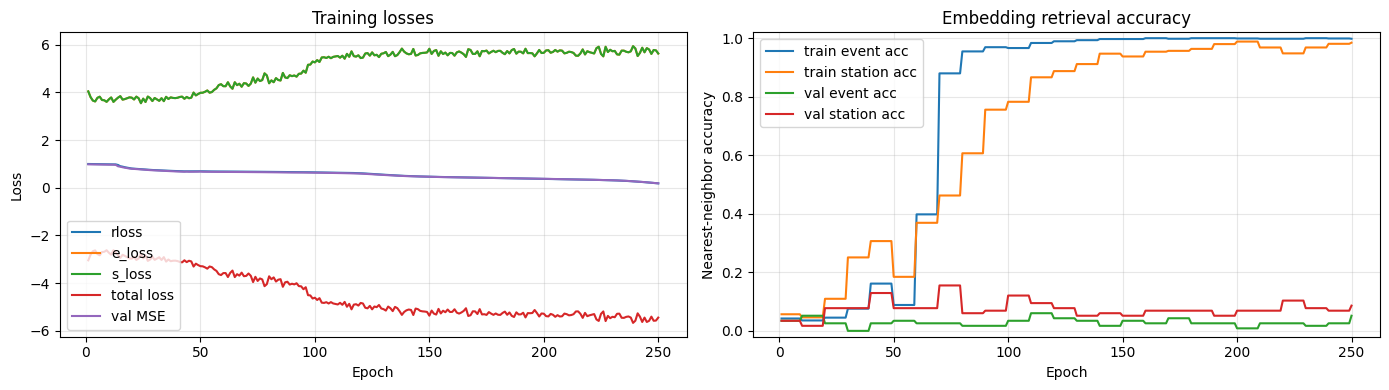

In [18]:
seed_everything(GLOBAL_SEED)
train_loader = make_data_loader(train_dataset, shuffle=True, seed=GLOBAL_SEED)

lambda_e = 0.05
lambda_s = 0.05

with torch.no_grad():
    sample_x = next(iter(train_loader_eval))

C = sample_x[0].shape[1]
L = sample_x[0].shape[2]

model = AE1D_Conv_MLP(C, L).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
mse = nn.MSELoss()

epochs = 250
plot_every = 10
acc_every = 10

history = {
    "epoch": [],
    "rloss": [],
    "e_loss": [],
    "s_loss": [],
    "loss": [],
    "val_MSE": [],
    "train_event_acc": [],
    "train_station_acc": [],
    "val_event_acc": [],
    "val_station_acc": [],
}

latest_acc = {
    "train_event_acc": np.nan,
    "train_station_acc": np.nan,
    "val_event_acc": np.nan,
    "val_station_acc": np.nan,
}

for ep in range(1, epochs + 1):
    model.train()

    train_loss_sum = 0.0
    train_rloss_sum = 0.0
    train_e_loss_sum = 0.0
    train_s_loss_sum = 0.0
    train_total = 0

    for data in train_loader:
        x = data[0]
        eids_b, sids_b = data[1], data[2]

        x = x.to(device, non_blocking=True)

        out = model(x)
        recon = out[0]
        z = out[1]

        D = z.shape[1]
        ze = z[:, :D // 2]
        zs = z[:, D // 2:]

        rloss = mse(recon, x)
        # e_loss = separation_loss(ze, eids_b, margin=0.2)
        # s_loss = separation_loss(zs, sids_b, margin=0.2)

        # loss = rloss + lambda_e * e_loss + lambda_s * s_loss
        s_loss=zs@zs.T
        e_loss=ze@ze.T
        matrix_e=pairwise_equal_matrix(id_list=eids_b,same_val= same_val,diff_val = diff_val).to(device)
        matrix_s=pairwise_equal_matrix(id_list=sids_b,same_val= same_val,diff_val = diff_val).to(device)
        
        closs= (s_loss*matrix_s+e_loss*matrix_e).mean()
        loss=rloss-closs

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        bs = x.size(0)
        train_loss_sum += loss.item() * bs
        train_rloss_sum += rloss.item() * bs
        train_e_loss_sum += closs.item() * bs
        train_s_loss_sum += closs.item() * bs
        train_total += bs

    train_loss = train_loss_sum / max(1, train_total)
    train_rloss = train_rloss_sum / max(1, train_total)
    train_e_loss = train_e_loss_sum / max(1, train_total)
    train_s_loss = train_s_loss_sum / max(1, train_total)

    val_loss = eval_epoch(val_loader)

    if ep == 1 or ep % acc_every == 0 or ep == epochs:
        latest_acc = compute_embedding_accuracies(model, train_loader_eval, val_loader_eval, device)

    history["epoch"].append(ep)
    history["rloss"].append(train_rloss)
    history["e_loss"].append(train_e_loss)
    history["s_loss"].append(train_s_loss)
    history["loss"].append(train_loss)
    history["val_MSE"].append(val_loss)
    history["train_event_acc"].append(latest_acc["train_event_acc"])
    history["train_station_acc"].append(latest_acc["train_station_acc"])
    history["val_event_acc"].append(latest_acc["val_event_acc"])
    history["val_station_acc"].append(latest_acc["val_station_acc"])

    # print(
    #     f"[Epoch {ep:04d}] "
    #     f"rloss={train_rloss:.6f}, "
    #     f"e_loss={train_e_loss:.6f}, "
    #     f"s_loss={train_s_loss:.6f}, "
    #     f"loss={train_loss:.6f}  "
    #     f"val_MSE={val_loss:.6f}  "
    #     f"train_e_acc={latest_acc['train_event_acc']:.3f}, "
    #     f"train_s_acc={latest_acc['train_station_acc']:.3f}, "
    #     f"val_e_acc={latest_acc['val_event_acc']:.3f}, "
    #     f"val_s_acc={latest_acc['val_station_acc']:.3f}"
    # )

    if ep == 1 or ep % plot_every == 0 or ep == epochs:
        live_plot_history(history)

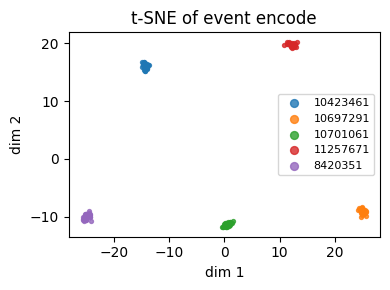

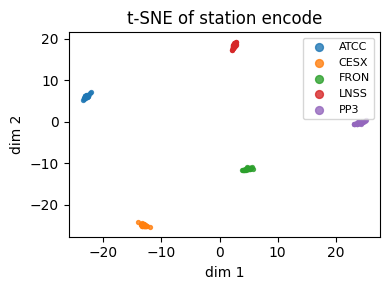

In [19]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# ---------- 1) Extract embeddings ----------
@torch.no_grad()
def extract_embeddings(model, loader, device):
    """
    Returns:
      ze_all: [N, De] event half
      zs_all: [N, Ds] station half
      eids_all: List[str] aligned with ze_all
      sids_all: List[str] aligned with zs_all
    Supports two batch structures:
      (x, evid_id, stid_id, eids_str, sids_str)  # 5 items
      (x, eids_str, sids_str)                     # 3 items
    """
    model.eval()
    ZEs, ZSs, all_eids, all_sids = [], [], [], []
    for batch in loader:
        if len(batch) == 5:
            x, _, _, eids_b, sids_b = batch
        elif len(batch) == 3:
            x, eids_b, sids_b = batch
        else:
            raise ValueError(f"Unexpected batch format with length {len(batch)}")

        x = x.to(device, non_blocking=True)
        out = model(x)
        z = out[1] if isinstance(out, (tuple, list)) else out

        # Split in half and apply L2 normalization.
        B, D = z.shape
        De = D // 2
        ze = torch.nn.functional.normalize(z[:, :De], dim=1)
        zs = torch.nn.functional.normalize(z[:, De:], dim=1)

        ZEs.append(ze.cpu())
        ZSs.append(zs.cpu())
        all_eids.extend([str(v) for v in eids_b])
        all_sids.extend([str(v) for v in sids_b])

    ze_all = torch.cat(ZEs, dim=0).numpy()
    zs_all = torch.cat(ZSs, dim=0).numpy()
    return ze_all, zs_all, np.array(all_eids, dtype=object), np.array(all_sids, dtype=object)


# ---------- 2) Select top-K labels deterministically and filter ----------
def filter_top_k(emb, labels, k=10):
    labels = np.asarray([str(v) for v in labels], dtype=object)
    cnt = Counter(labels)
    top = {
        lab
        for lab, _ in sorted(cnt.items(), key=lambda item: (-item[1], item[0]))[:k]
    }
    keep = np.array([lab in top for lab in labels], dtype=bool)
    return emb[keep], labels[keep]


# ---------- 3) Dimensionality reduction (prefer t-SNE, fallback to PCA) ----------
def reduce_2d(X, perplexity=30, random_state=TSNE_SEED):
    X = np.asarray(X, dtype=np.float32)
    if len(X) <= 2:
        raise ValueError("Need at least 3 points for 2D embedding visualization.")

    # Keep perplexity valid and deterministic for small filtered subsets.
    perplexity = min(int(perplexity), max(1, (len(X) - 1) // 3))

    try:
        from sklearn.manifold import TSNE
        X2 = TSNE(
            n_components=2,
            perplexity=perplexity,
            init="pca",
            learning_rate="auto",
            random_state=random_state,
            method="exact",
            n_jobs=1,
        ).fit_transform(X)
        method = "t-SNE"
    except Exception:
        # fallback: deterministic PCA
        Xc = X - X.mean(axis=0, keepdims=True)
        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        X2 = Xc @ Vt[:2].T
        method = "PCA"
    return X2, method


# ---------- 4) Plot (color by label) ----------
def plot_embedding(X2, labels, title, max_legend=10, figsize=(4,3)):
    labels = np.asarray([str(v) for v in labels], dtype=object)
    uniq = np.array(sorted(set(labels), key=str))

    # Assign colors deterministically by sorted label order.
    prop_cycle = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
    if len(prop_cycle) < len(uniq):
        from matplotlib import cm
        cmap = cm.get_cmap('tab20', len(uniq))
        colors = [cmap(i) for i in range(len(uniq))]
    else:
        colors = prop_cycle[:len(uniq)]

    color_map = {lab: colors[i % len(colors)] for i, lab in enumerate(uniq)}

    plt.figure(figsize=figsize)
    for lab in uniq:
        pts = X2[labels == lab]
        plt.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.8, label=str(lab),
                    color=color_map[lab])
    plt.title(title)
    plt.xlabel("dim 1"); plt.ylabel("dim 2")
    # Show only the first max_legend legend entries to avoid clutter.
    if len(uniq) <= max_legend:
        plt.legend(markerscale=2, fontsize=8, frameon=True)
    else:
        sub = ", ".join(map(str, uniq[:max_legend]))
        plt.suptitle(f"Showing legend for first {max_legend}: {sub}", y=0.02, fontsize=8)
    plt.tight_layout()
    plt.show()


# ---------- 5) One-shot run: extract -> filter -> reduce -> plot ----------
# Use the non-shuffled evaluation loader so the input order to t-SNE is stable.
ze_all, zs_all, eids_all, sids_all = extract_embeddings(model, train_loader_eval, device)

# Select the top-K labels deterministically.
K = 5
ze_e, eids_e = filter_top_k(ze_all, eids_all, k=K)  # filter by eid
zs_s, sids_s = filter_top_k(zs_all, sids_all, k=K)  # filter by sid

# Dimensionality reduction.
ze_2d, m1 = reduce_2d(ze_e, perplexity=30, random_state=TSNE_SEED)
zs_2d, m2 = reduce_2d(zs_s, perplexity=30, random_state=TSNE_SEED)

# Plot: color ze by eid; color zs by sid.
plot_embedding(ze_2d, eids_e, title=f"{m1} of event encode", max_legend=K)
plot_embedding(zs_2d, sids_s, title=f"{m2} of station encode", max_legend=K)


In [20]:
ze_all, zs_all, eids_all, sids_all = extract_embeddings(model, train_loader_eval, device)

print("event embedding std:", ze_all.std(axis=0).mean())
print("station embedding std:", zs_all.std(axis=0).mean())

print("rounded unique event embeddings:", np.unique(np.round(ze_all, 4), axis=0).shape[0])
print("rounded unique station embeddings:", np.unique(np.round(zs_all, 4), axis=0).shape[0])

event embedding std: 0.11771943
station embedding std: 0.124073885
rounded unique event embeddings: 1040
rounded unique station embeddings: 1040


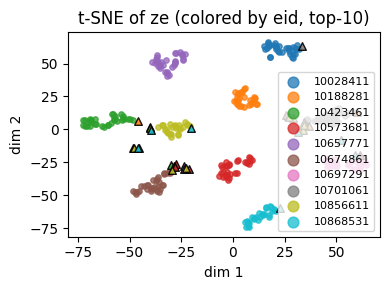

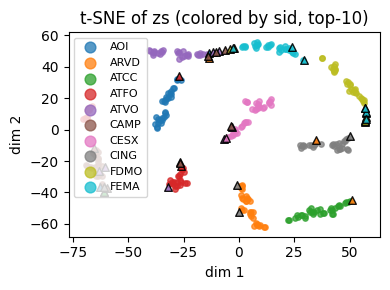

In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from typing import Tuple, List, Dict

# ============== Core: extraction ==============
@torch.no_grad()
def extract_embeddings(model, loader, device) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Returns:
        ze_all: [N, De] event embedding (first half)
        zs_all: [N, Ds] station embedding (second half)
        eids_all: (N,) object array of Python strings
        sids_all: (N,) object array of Python strings
    Supported batch formats:
      - (x, evid_id, stid_id, eids_str, sids_str)
      - (x, eids_str, sids_str)
    """
    model.eval()
    ZEs, ZSs, all_eids, all_sids = [], [], [], []
    for batch in loader:
        if len(batch) == 5:
            x, _, _, eids_b, sids_b = batch
        elif len(batch) == 3:
            x, eids_b, sids_b = batch
        else:
            raise ValueError(f"Unexpected batch format: len={len(batch)}")

        x = x.to(device, non_blocking=True)
        out = model(x)
        z = out[1] if isinstance(out, (tuple, list)) else out  # if the model returns z directly

        B, D = z.shape
        De = D // 2
        ze = torch.nn.functional.normalize(z[:, :De], dim=1)
        zs = torch.nn.functional.normalize(z[:, De:], dim=1)

        ZEs.append(ze.cpu())
        ZSs.append(zs.cpu())
        all_eids.extend([str(v) for v in eids_b])
        all_sids.extend([str(v) for v in sids_b])

    ze_all = torch.cat(ZEs, dim=0).numpy()
    zs_all = torch.cat(ZSs, dim=0).numpy()
    return ze_all, zs_all, np.array(all_eids, dtype=object), np.array(all_sids, dtype=object)

# ============== Selection/filtering ==============
def topk_union(train_labels: np.ndarray, val_labels: np.ndarray, k: int) -> List[str]:
    labels = [str(x) for x in list(train_labels) + list(val_labels)]
    cnt = Counter(labels)
    return [
        lab
        for lab, _ in sorted(cnt.items(), key=lambda item: (-item[1], item[0]))[:k]
    ]

def filter_by_labels(X: np.ndarray, labels: np.ndarray, keep_labels: List[str]) -> Tuple[np.ndarray, np.ndarray]:
    labels = np.asarray([str(x) for x in labels], dtype=object)
    keep_labels = [str(x) for x in keep_labels]
    keep = np.isin(labels, keep_labels)
    return X[keep], labels[keep]

# ============== Dimensionality reduction ==============
def reduce_2d(X: np.ndarray, perplexity: int = 30, random_state: int = TSNE_SEED) -> Tuple[np.ndarray, str]:
    X = np.asarray(X, dtype=np.float32)
    if len(X) <= 2:
        raise ValueError("Need at least 3 points for 2D embedding visualization.")

    # Keep perplexity valid and deterministic for small filtered subsets.
    perplexity = min(int(perplexity), max(1, (len(X) - 1) // 3))

    try:
        from sklearn.manifold import TSNE
        X2 = TSNE(
            n_components=2,
            perplexity=perplexity,
            init="pca",
            learning_rate="auto",
            random_state=random_state,
            method="exact",
            n_jobs=1,
        ).fit_transform(X)
        method = "t-SNE"
    except Exception:
        Xc = X - X.mean(axis=0, keepdims=True)
        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        X2 = Xc @ Vt[:2].T
        method = "PCA"
    return X2, method

# ============== Color mapping (shared across train/val) ==============
def make_color_map(labels_order: List[str]) -> Dict[str, tuple]:
    labels_order = [str(lab) for lab in labels_order]
    K = len(labels_order)
    cmap_name = "tab10" if K <= 10 else "tab20"
    cmap = plt.get_cmap(cmap_name, K)
    return {lab: cmap(i) for i, lab in enumerate(labels_order)}

# ============== Plotting: train=circle, val=triangle ==============
def plot_train_val(Xtr: np.ndarray, Ltr: np.ndarray,
                   Xva: np.ndarray, Lva: np.ndarray,
                   title: str, labels_order: List[str],
                   figsize=(6, 5), max_legend: int = 10):
    labels_order = [str(lab) for lab in labels_order]
    color_map = make_color_map(labels_order)
    Ltr = np.asarray([str(x) for x in Ltr], dtype=object)
    Lva = np.asarray([str(x) for x in Lva], dtype=object)

    plt.figure(figsize=figsize)
    # Training set: circles
    for lab in labels_order:
        pts = Xtr[Ltr == lab]
        if len(pts) > 0:
            plt.scatter(pts[:, 0], pts[:, 1], s=15, marker='o',
                        color=color_map[lab], alpha=0.75, label=str(lab))
    # Validation set: triangles
    for lab in labels_order:
        pts = Xva[Lva == lab]
        if len(pts) > 0:
            plt.scatter(pts[:, 0], pts[:, 1], s=30, marker='^',
                        facecolors=color_map[lab], edgecolors='k', alpha=0.9)

    plt.title(title)
    plt.xlabel("dim 1"); plt.ylabel("dim 2")
    if len(labels_order) <= max_legend:
        plt.legend(markerscale=2, fontsize=8, frameon=True)
    else:
        sub = ", ".join(map(str, labels_order[:max_legend]))
        plt.suptitle(f"Legend shows first {max_legend}: {sub}", y=0.02, fontsize=8)
    plt.tight_layout()
    plt.show()

# ============== One-shot visualization ==============
def visualize_embeddings(model, train_loader, val_loader, device,
                         topk: int = 10, perplexity: int = 30, random_state: int = TSNE_SEED):
    """
    Plot two figures:
      1) ze colored by eid (train=circle, val=triangle)
      2) zs colored by sid (train=circle, val=triangle)
    Colors are consistent between train and val; Top-K is deterministic and
    based on train+val frequency with alphabetical tie-breaking.
    """
    # Extract from non-shuffled loaders for reproducible input order.
    ze_tr, zs_tr, eids_tr, sids_tr = extract_embeddings(model, train_loader, device)
    ze_va, zs_va, eids_va, sids_va = extract_embeddings(model, val_loader, device)

    # ---- ze | eid ----
    eid_keep = topk_union(eids_tr, eids_va, topk)
    ze_tr_f, eids_tr_f = filter_by_labels(ze_tr, eids_tr, eid_keep)
    ze_va_f, eids_va_f = filter_by_labels(ze_va, eids_va, eid_keep)

    ze_all = np.vstack([ze_tr_f, ze_va_f])
    ze_2d, method_e = reduce_2d(ze_all, perplexity=perplexity, random_state=random_state)
    ze_tr_2d, ze_va_2d = ze_2d[:len(ze_tr_f)], ze_2d[len(ze_tr_f):]
    plot_train_val(ze_tr_2d, eids_tr_f, ze_va_2d, eids_va_f,
                   title=f"{method_e} of ze (colored by eid, top-{topk})",
                   labels_order=eid_keep, figsize=(4,3), max_legend=topk)

    # ---- zs | sid ----
    sid_keep = topk_union(sids_tr, sids_va, topk)
    zs_tr_f, sids_tr_f = filter_by_labels(zs_tr, sids_tr, sid_keep)
    zs_va_f, sids_va_f = filter_by_labels(zs_va, sids_va, sid_keep)

    zs_all = np.vstack([zs_tr_f, zs_va_f])
    zs_2d, method_s = reduce_2d(zs_all, perplexity=perplexity, random_state=random_state)
    zs_tr_2d, zs_va_2d = zs_2d[:len(zs_tr_f)], zs_2d[len(zs_tr_f):]
    plot_train_val(zs_tr_2d, sids_tr_f, zs_va_2d, sids_va_f,
                   title=f"{method_s} of zs (colored by sid, top-{topk})",
                   labels_order=sid_keep, figsize=(4,3), max_legend=topk)

# ============== Usage example ==============
visualize_embeddings(model, train_loader_eval, val_loader_eval, device,
                     topk=10, perplexity=5, random_state=TSNE_SEED)


In [22]:
eids_b

['7731641',
 '8420351',
 '9150631',
 '9271231',
 '10868531',
 '10423461',
 '10697291',
 '11725751',
 '10868531',
 '8420351',
 '9271231',
 '9882931',
 '10697291',
 '9862071',
 '9008551',
 '9150631']